# 09 Final NASA test evaluation

NASA C-MAPSS FD001. All nine candidate definitions, estimator settings, and blend weights were fixed before evaluating the NASA test endpoints. This notebook reads the saved evaluation artifacts.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd()
if not (root / "reports").is_dir():
    root = root.parent
test_dir = root / "reports" / "final_test_evaluation"
insights_dir = root / "reports" / "final_insights"

## A. Full training and stacking

The baseline inputs are operating cycle and the selected 14 sensor readings. Linear Regression fits a StandardScaler inside the training pipeline. Both tree families use unscaled inputs. Their enhanced versions use the 99-feature causal transformation from Step C1.

The stacking meta-model is a Linear Regression trained on predictions from the original five engine-held-out training folds. Each base model is then fitted on the full training set. The simple, weighted, and final hybrid blends use the full-data base estimators and the weights from their cross-validation experiments.

To regenerate the saved outputs from the project root, run `python -m src.final_test_evaluation fit` followed by `python -m src.final_test_evaluation evaluate`.

In [2]:
manifest = json.loads((test_dir / "models" / "manifest.json").read_text())
display(pd.DataFrame([{
    "Training rows": manifest["training_rows"], "Training engines": manifest["training_engines"],
    "Meta-training folds": manifest["n_splits"], "Enhanced candidate": manifest["hybrid_name"],
}]))
blend_rows = [{"Blend": blend, "Component": model, "Weight": weight}
              for blend, weights in manifest["blends"].items() for model, weight in weights.items()]
display(pd.DataFrame(blend_rows))

,Training rows,Training engines,Meta-training folds,Enhanced candidate
0,20631,100,5,Enhanced equal average


,Blend,Component,Weight
0,simple_averaging,random_forest,0.5
1,simple_averaging,xgboost,0.5
2,weighted_averaging,random_forest,0.3
3,weighted_averaging,xgboost,0.7
4,final_hybrid_model,enhanced_random_forest,0.5
5,final_hybrid_model,enhanced_xgboost,0.5


## B. One endpoint and one label per engine

The same trailing feature transformation runs on the entire available history of each test engine before selecting its maximum observed cycle. The one-based row position in the NASA label file equals the engine ID. Evaluation checks the original engine order, the endpoint cycle, and one-to-one alignment.

In [3]:
alignment = pd.read_csv(test_dir / "test_label_alignment.csv")
protocol = json.loads((test_dir / "evaluation_protocol.json").read_text())
assert alignment["unit_number"].tolist() == list(range(1, 101))
assert len(alignment) == protocol["test_engines"]
display(pd.concat([alignment.head(3), alignment.tail(3)], ignore_index=True))

,unit_number,last_observed_cycle,actual_RUL
0,1,31,112
1,2,49,98
2,3,126,69
3,98,121,59
4,99,97,117
5,100,198,20


## C. NASA test metrics

Each metric below uses the 100 held-out engine endpoints. The PHM score penalizes overestimation more heavily than underestimation. [Scoring reference](https://ntrs.nasa.gov/api/citations/20205001125/downloads/Run_to_Failure_Simulation_Under_Real_Flight_Conditions_Dataset.pdf)

Cross-validation values are stored separately and summarize validation cycles across engines.

,Model,MAE,RMSE,R²,NASA Score
0,Linear Regression,25.8641,31.1290,0.4389,6823.2579
1,Random Forest,20.0208,26.6729,0.5880,11281.1836
2,XGBoost,18.3631,25.6863,0.6179,6679.9435
3,Simple Averaging,19.1048,25.9516,0.6100,7895.5216
4,Weighted Averaging,18.7903,25.7894,0.6149,7198.3198
5,Stacking,19.2814,25.9519,0.6100,6096.5369
6,Enhanced Random Forest,20.6236,29.7036,0.4891,159059.6737
7,Enhanced XGBoost,20.1230,27.6070,0.5587,18770.6459
8,Final Hybrid Model,20.0719,28.1111,0.5424,48663.7451


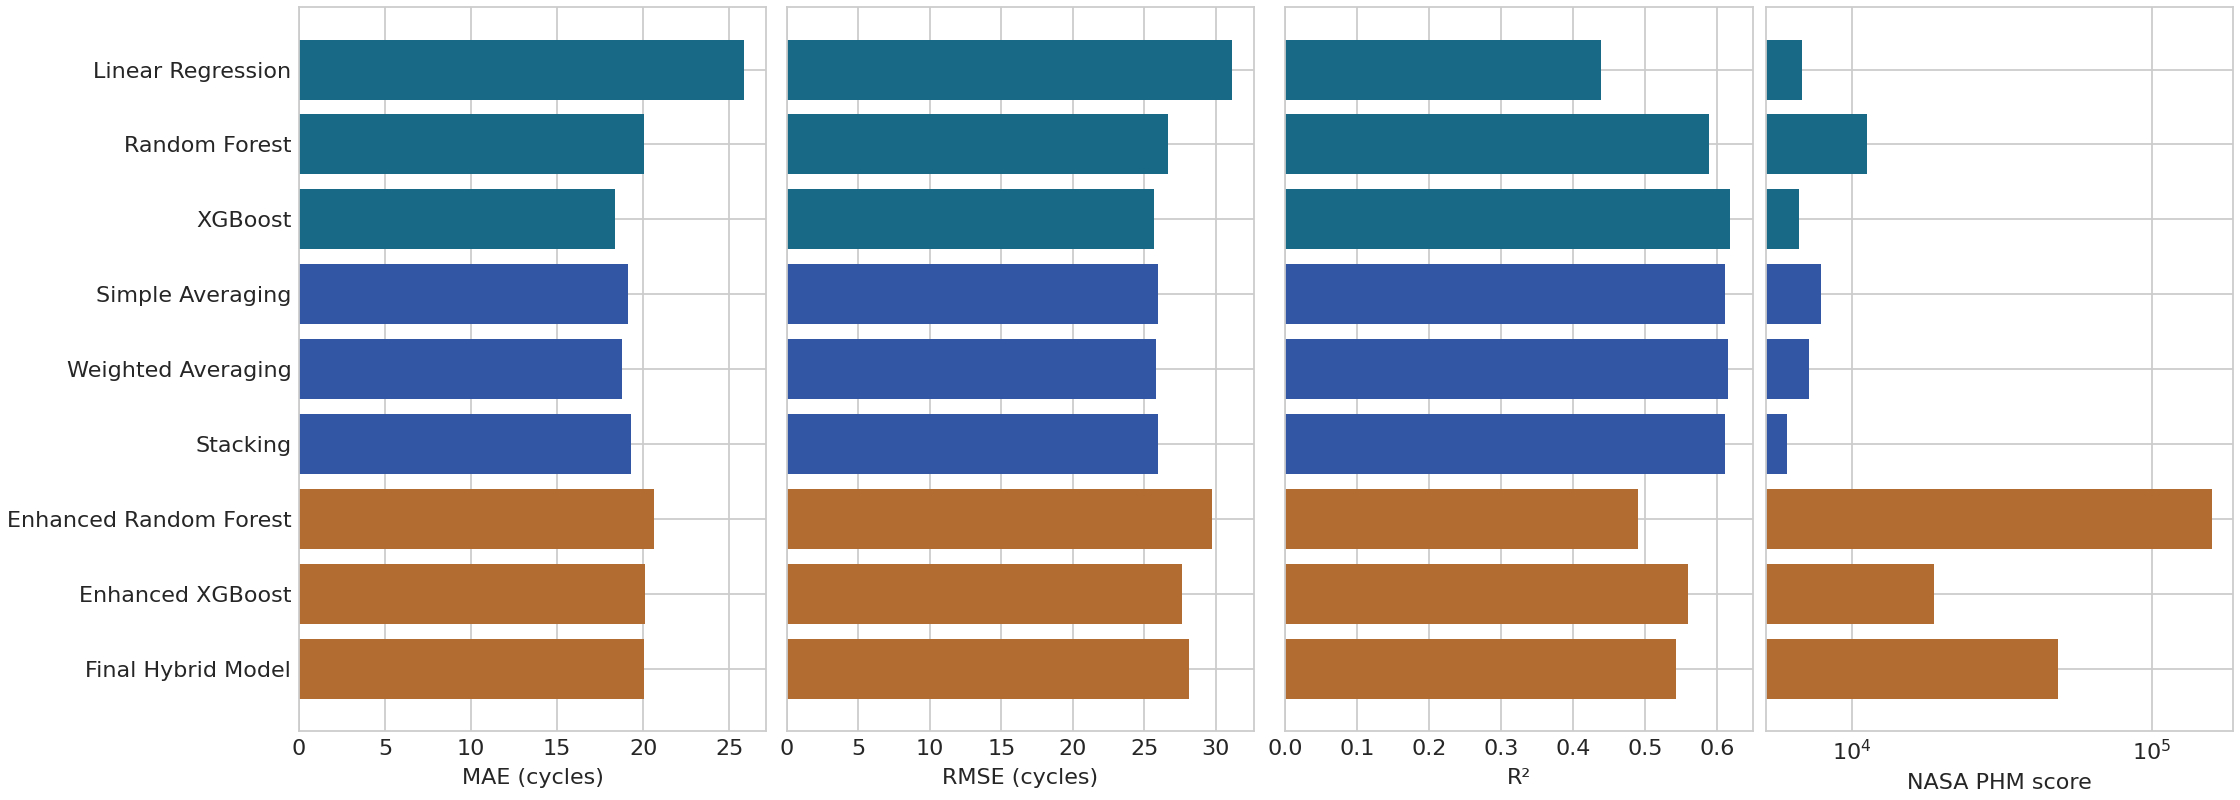

In [4]:
test = pd.read_csv(test_dir / "test_metrics.csv")
display(test[["Model", "MAE", "RMSE", "R2", "NASA Score"]].rename(columns={"R2": "R²"}).round(4))
display(Image(filename=str(test_dir / "test_metric_comparison.png")))

## D. Predictions and diagnostics

The dashed diagonal marks exact predictions. Residuals are actual minus predicted RUL. The distribution chart shows the signed prediction error, predicted minus actual, on a common scale.

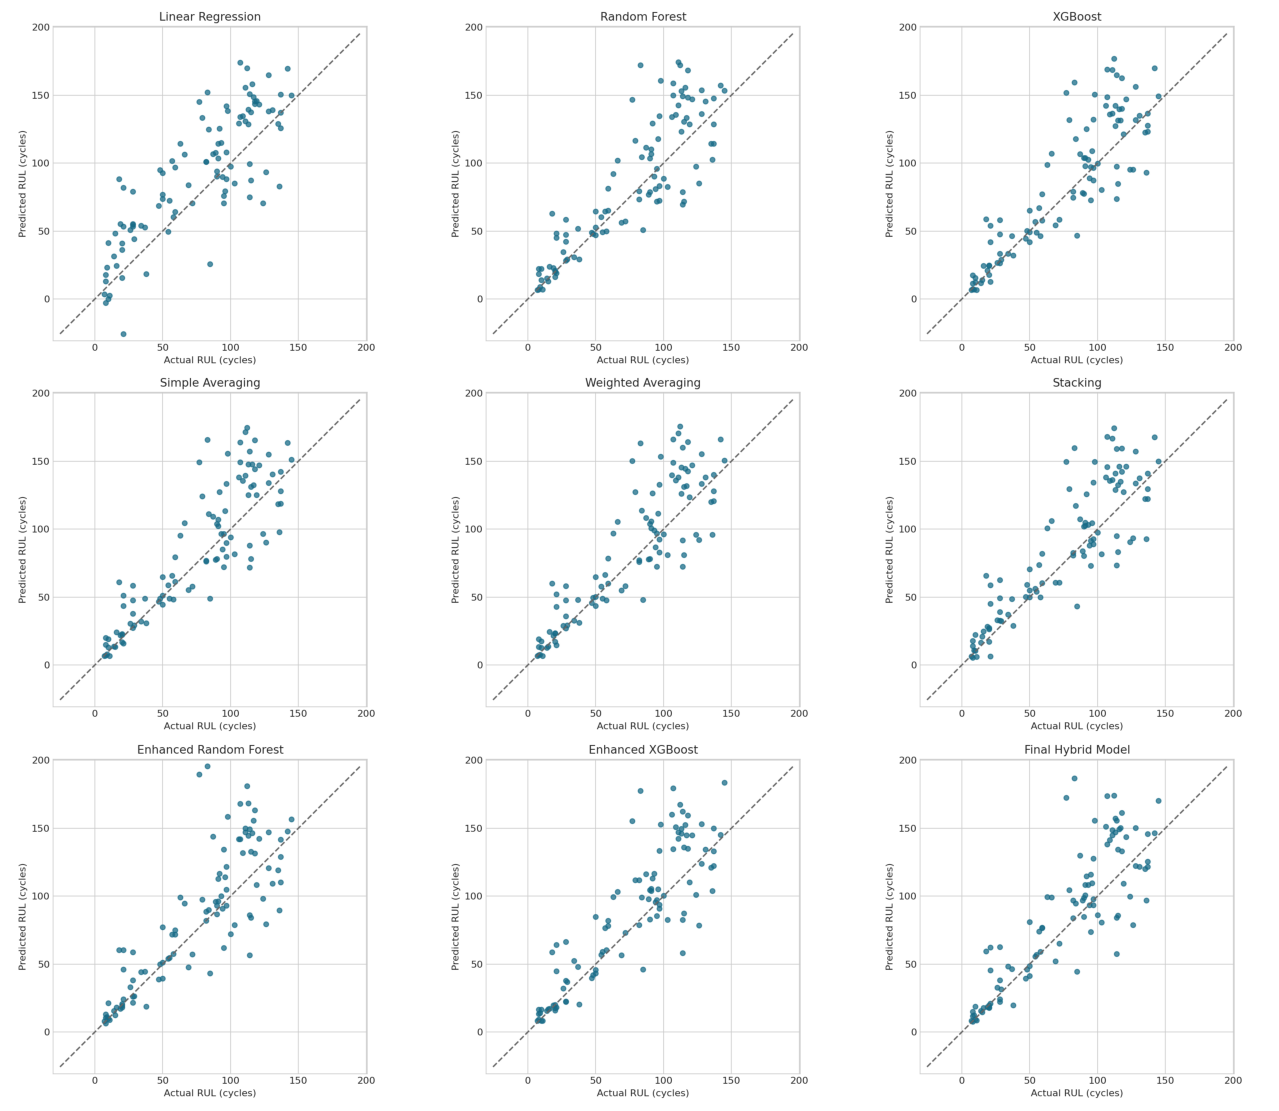

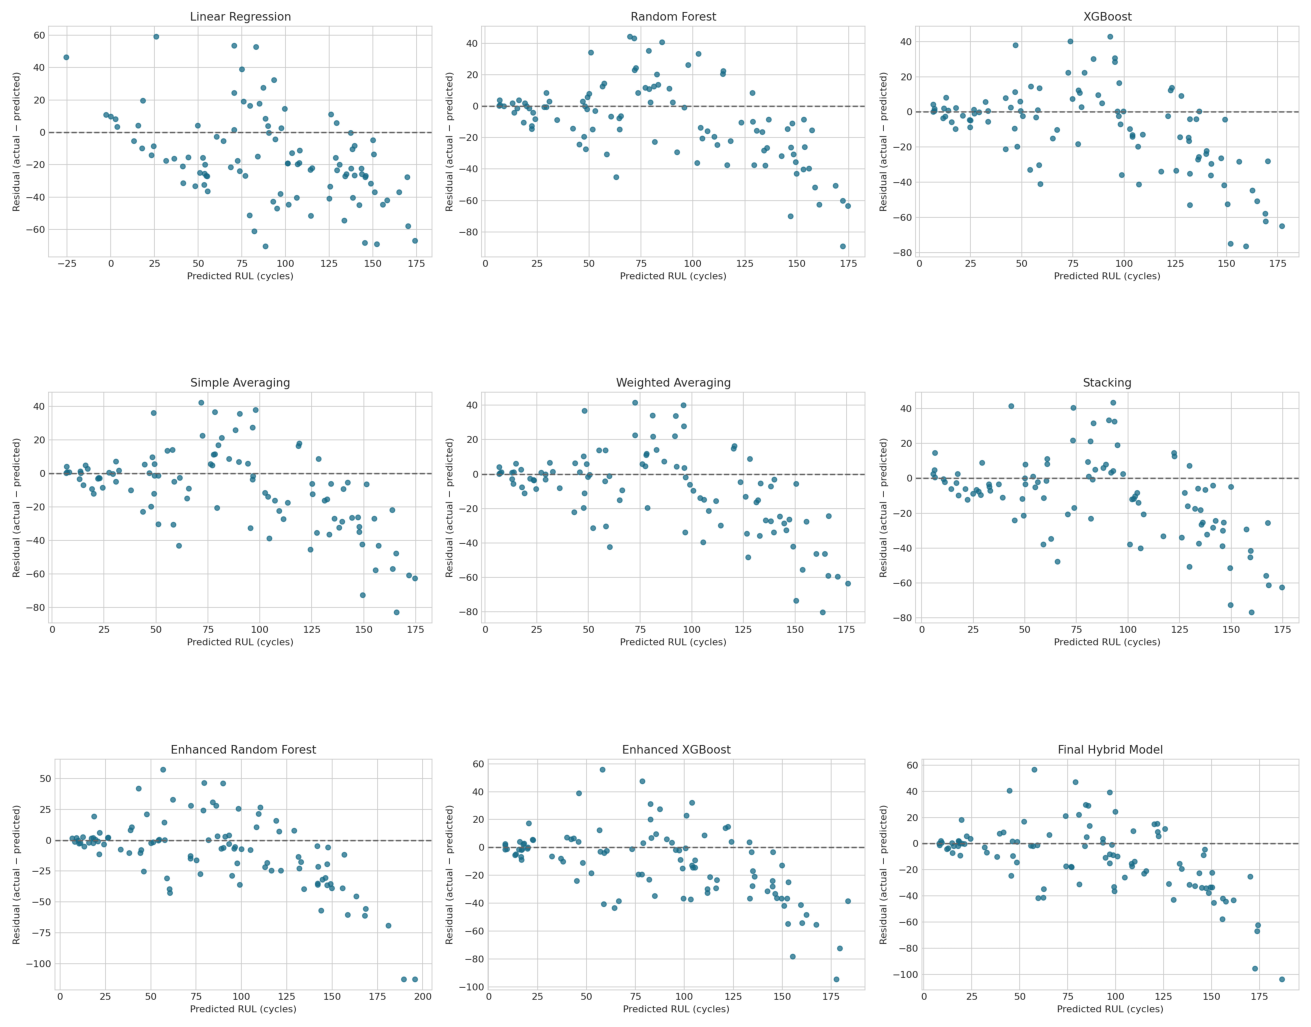

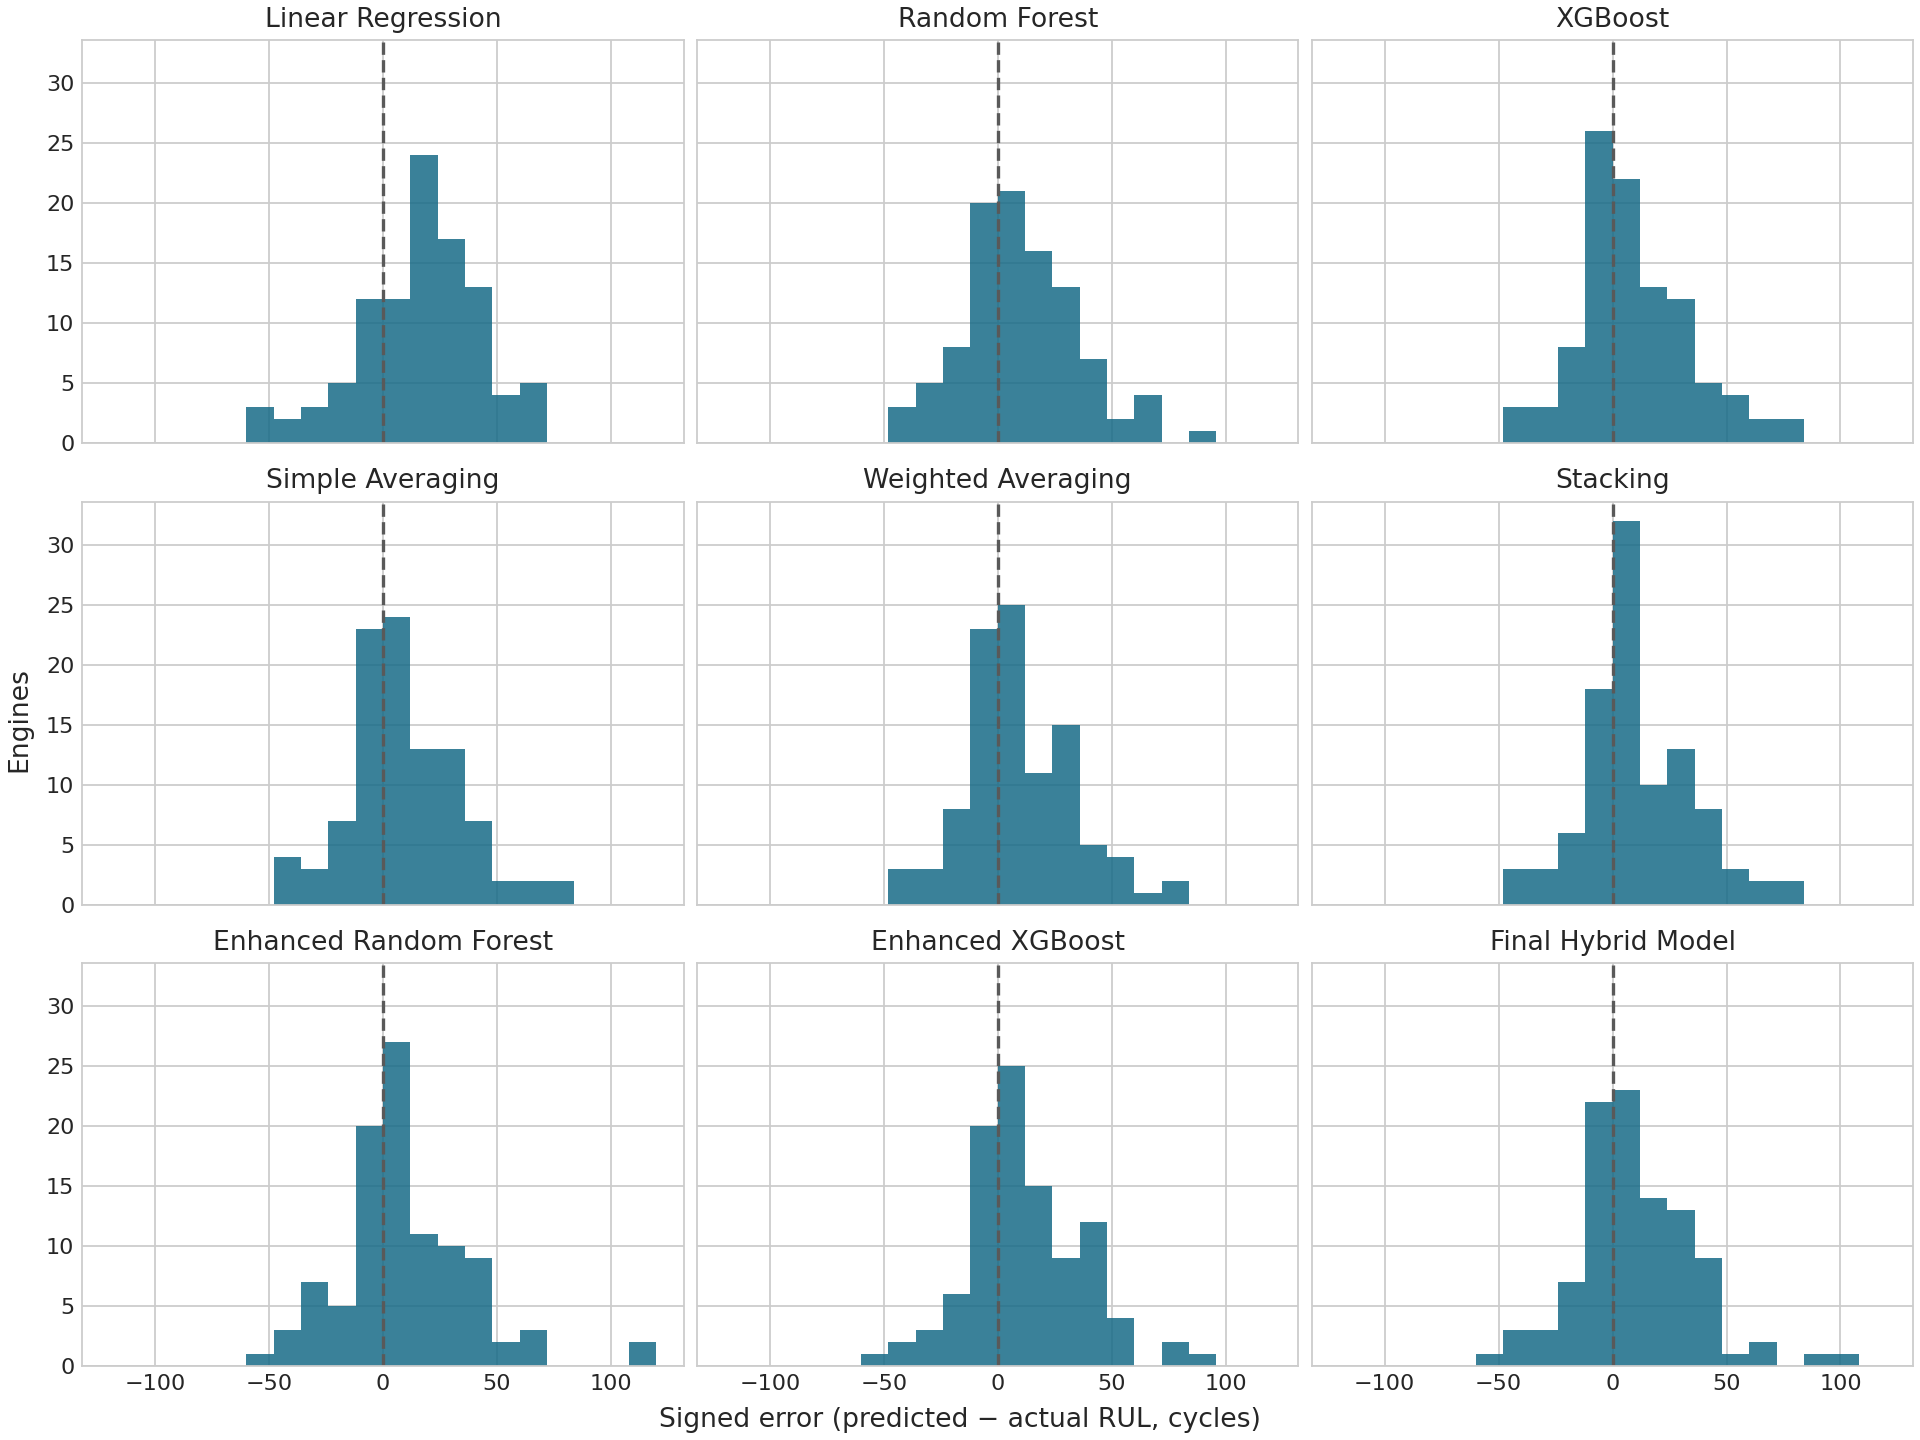

In [5]:
def show_model_panels(filename):
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout="constrained")
    for ax, key in zip(axes.flat, test["model_id"], strict=True):
        ax.imshow(plt.imread(test_dir / "figures" / key / filename))
        ax.axis("off")
    display(fig)
    plt.close(fig)

show_model_panels("actual_vs_predicted.png")
show_model_panels("residuals.png")
display(Image(filename=str(test_dir / "error_distributions.png")))

In [6]:
predictions = pd.read_csv(test_dir / "test_predictions.csv")
preview = predictions.loc[predictions["unit_number"].le(2),
                          ["Model", "unit_number", "last_observed_cycle",
                           "actual_RUL", "predicted_RUL", "absolute_error"]]
display(preview.round(3))

,Model,unit_number,last_observed_cycle,actual_RUL,predicted_RUL,absolute_error
0,Linear Regression,1,31,112,169.964,57.964
1,Linear Regression,2,49,98,138.468,40.468
100,Random Forest,1,31,112,172.170,60.170
101,Random Forest,2,49,98,160.710,62.710
200,XGBoost,1,31,112,176.933,64.933
201,XGBoost,2,49,98,150.495,52.495
300,Simple Averaging,1,31,112,174.552,62.552
301,Simple Averaging,2,49,98,155.602,57.602
400,Weighted Averaging,1,31,112,175.504,63.504
401,Weighted Averaging,2,49,98,153.559,55.559


The evaluation folder contains the full model checkpoints, the ensemble manifest, training-side stacking predictions, alignment audit, comparison table, and one detailed prediction CSV per model.